In [1]:
import os
import pandas as pd
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, END
from langgraph.graph.message import add_messages
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, SystemMessage
from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder

In [ ]:
model="openai/gpt-oss-120b"
GROQ_API_KEY="OSE"

In [ ]:

SYSTEM_PROMPT = """You are an expert data scientist and data-quality decision maker.

You receive:

1. A dataset summary containing evidence about the actual data.
2. A user-specified use case describing what the data will be used for.

Your job is to decide what cleaning is actually justified for this dataset and use case.

==================================================
CORE RULE
==================================================

Understand the data CONTEXT before making any cleaning decision.

Statistics such as null percentage, uniqueness, frequency, distributions, or cardinality are signals for investigation, NOT automatic reasons to modify data.

Never change, fill, replace, drop, or delete data simply because a statistical value crosses a threshold.

Before making any change, consider:

- What does the column or row represent?
- What do the actual values mean?
- Is the value/pattern actually wrong?
- Could it be meaningful?
- Does the issue matter for the stated use case?
- Could changing it destroy useful information?
- Is there enough evidence to safely modify it?

If there is not enough evidence, PRESERVE the data and mark it as "Needs validation".

==================================================
DATA PRESERVATION
==================================================

Prefer preserving original information.

Be especially careful before:

- filling missing values
- dropping rows
- dropping columns
- deleting duplicates
- removing outliers
- replacing values
- changing categories
- removing IDs
- modifying dates
- aggregating records

These actions require strong evidence.

Use the least destructive valid action whenever possible.

==================================================
IMPORTANT
==================================================

Do not assume:

- high null percentage means a column should be dropped
- low population means a column is useless
- an outlier is an error
- a duplicate is accidental
- an ID should be removed
- a rare category is noise
- a zero is invalid
- a missing value should be filled
- high cardinality means a column is useless

Always interpret the finding using the column meaning, actual values, relationships with other columns, and the dataset context.

==================================================
USE CASE
==================================================

Use the user's purpose to determine whether an issue matters.

Consider the appropriate requirements for:

- Machine learning / prediction
- Data analysis
- Data visualization
- Business reporting
- Financial / transaction analysis
- Time-series analysis
- Database / data integration
- Scientific / experimental analysis
- Custom user-defined purposes

The use case guides the decision, but it does not justify unnecessary data modification.

==================================================
ISSUE DECISION
==================================================

For every important issue, determine:

1. What is the issue?
2. What evidence supports it?
3. What does it mean in the context of the data?
4. Does it matter for the use case?
5. Should it be fixed, preserved, or validated?
6. If changed, what is the least destructive appropriate action?

Only recommend a modification when the evidence and context justify it.

==================================================
OUTPUT
==================================================

Output only:

USE CASE
- stated use case | objective

ISSUES
- column: problem | evidence | use-case impact | action | reason

DROP
- column/rows: reason
- Only include strongly justified deletions.

TYPE
- column → target dtype | handling | reason

CLEANING PLAN
- exact operations required

PRESERVE
- data that should remain unchanged | reason

VALIDATION
- issue | why it cannot safely be decided automatically

OBSERVATIONS
- important dataset-specific considerations

==================================================
FINAL RULE
==================================================
Hey see if user gives you prompt how to clean the dataset or for what purpose user want to clean the dataset then 
do the cleaning according to given description and try to follow its amplication and rules 

Do not try to make the dataset look perfect.

Make it trustworthy for its intended use while preserving valuable information.

When evidence is insufficient:

PRESERVE THE DATA.
MARK IT AS "Needs validation".

Do not write Python.
Do not repeat the dataset summary.
Do not give generic preprocessing advice.
Do not invent assumptions.
Be concise and precise.
"""


In [12]:
import pandas as pd
import numpy as np

def summarize_csv(
    path: str,
    sample_rows: int = 5,
    random_sample_fraction: float = 0.1,
    random_state: int = 42,
) -> str:
    df = pd.read_csv(path)
    lines = []

    # ---------- 1. Basic Info ----------
    lines.append("BASIC INFO:")
    lines.append(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    lines.append(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    lines.append(f"Column names: {', '.join(df.columns.astype(str))}")

    # ---------- 2. Dtypes ----------
    lines.append("\nCOLUMN DATA TYPES:")
    lines.append(df.dtypes.to_string())

    # ---------- 3. Missing Values ----------
    lines.append("\nMISSING VALUES:")
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
    missing_df = missing_df[missing_df["missing_count"] > 0].sort_values("missing_count", ascending=False)
    lines.append(missing_df.to_string() if not missing_df.empty else "No missing values.")

    # ---------- 4. Duplicates ----------
    lines.append(f"\nFully duplicate rows: {df.duplicated().sum()}")

    # ---------- 5. Constant / near-constant columns ----------
    lines.append("\nCONSTANT / SINGLE-VALUE COLUMNS:")
    constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
    lines.append(", ".join(constant_cols) if constant_cols else "None")

    # ---------- 6. Numeric column stats ----------
    num_df = df.select_dtypes(include=np.number)
    if not num_df.empty:
        lines.append("\nNUMERIC COLUMNS - SUMMARY STATISTICS:")
        lines.append(num_df.describe().transpose().to_string())

        lines.append("\nNUMERIC COLUMNS - SKEWNESS & KURTOSIS:")
        skew_kurt = pd.DataFrame({
            "skewness": num_df.skew(),
            "kurtosis": num_df.kurtosis()
        })
        lines.append(skew_kurt.to_string())

        # Outlier detection using IQR
        lines.append("\nNUMERIC COLUMNS - OUTLIER COUNTS (IQR method):")
        outlier_info = []
        for col in num_df.columns:
            q1, q3 = num_df[col].quantile(0.25), num_df[col].quantile(0.75)
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            outliers = ((num_df[col] < lower) | (num_df[col] > upper)).sum()
            outlier_info.append(f"{col}: {outliers} outliers ({(outliers/len(df)*100):.2f}%)")
        lines.append("\n".join(outlier_info) if outlier_info else "No numeric columns.")

        # Correlation matrix (only if more than 1 numeric column)
        if num_df.shape[1] > 1:
            lines.append("\nNUMERIC COLUMNS - CORRELATION MATRIX:")
            lines.append(num_df.corr().round(2).to_string())
    else:
        lines.append("\nNUMERIC COLUMNS: No numeric columns found.")

    # ---------- 7. Categorical / object column stats ----------
    cat_df = df.select_dtypes(include=["object", "category"])
    if not cat_df.empty:
        lines.append("\nCATEGORICAL COLUMNS - CARDINALITY & TOP VALUES:")
        for col in cat_df.columns:
            nunique = df[col].nunique(dropna=True)
            top_values = df[col].value_counts(dropna=True).head(5)
            lines.append(f"\nColumn: {col}")
            lines.append(f"  Unique values: {nunique}")
            lines.append(f"  High cardinality (>50% unique): {'YES' if nunique > 0.5 * len(df) else 'No'}")
            lines.append(f"  Top 5 values:\n{top_values.to_string()}")
    else:
        lines.append("\nCATEGORICAL COLUMNS: No categorical columns found.")

    # ---------- 8. Potential mixed-type columns ----------
    lines.append("\nPOTENTIAL MIXED-TYPE COLUMNS:")
    mixed_type_cols = []
    for col in df.columns:
        types_in_col = df[col].dropna().map(type).nunique()
        if types_in_col > 1:
            mixed_type_cols.append(col)
    lines.append(", ".join(mixed_type_cols) if mixed_type_cols else "None")

    # ---------- 9. Columns that look numeric but stored as object ----------
    lines.append("\nCOLUMNS THAT MIGHT BE MIS-TYPED (numeric-looking strings):")
    suspicious_numeric = []
    for col in cat_df.columns:
        non_null = df[col].dropna()
        if len(non_null) == 0:
            continue
        convertible = pd.to_numeric(non_null, errors="coerce").notna().mean()
        if convertible > 0.9:
            suspicious_numeric.append(f"{col} ({convertible*100:.1f}% convertible to numeric)")
    lines.append("\n".join(suspicious_numeric) if suspicious_numeric else "None detected")

    # ---------- 10. Date-like columns ----------
    lines.append("\nCOLUMNS THAT MIGHT BE DATES (stored as object):")
    suspicious_dates = []
    for col in cat_df.columns:
        non_null = df[col].dropna().astype(str)
        if len(non_null) == 0:
            continue
        try:
            convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
            if convertible > 0.9:
                suspicious_dates.append(f"{col} ({convertible*100:.1f}% convertible to datetime)")
        except Exception:
            pass
    lines.append("\n".join(suspicious_dates) if suspicious_dates else "None detected")

    # ---------- 11. Sample rows (small preview, from the head) ----------
    lines.append(f"\nSAMPLE ROWS (first {sample_rows}):")
    lines.append(df.head(sample_rows).to_string())

    # ---------- 12. Random sample of rows (for deeper understanding) ----------
    n_random = int(len(df) * random_sample_fraction)
    lines.append(f"\nRANDOM SAMPLE ({int(random_sample_fraction*100)}% of rows = {n_random} rows, random_state={random_state}):")
    random_sample_df = df.sample(frac=random_sample_fraction, random_state=random_state).sort_index()
    lines.append(random_sample_df.to_string())

    return "\n".join(lines)

In [13]:
# Improved Less Tokenize Function
def summarize_csv(
    path: str,
    sample_rows: int = 5,
    max_random_rows: int = 10,   # fixed cap, not a % of the dataset
    random_state: int = 42,
) -> str:
    df = pd.read_csv(path)
    lines = []

    # ---------- 1. Basic Info ----------
    lines.append("BASIC INFO:")
    lines.append(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
    lines.append(f"Memory usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")
    lines.append(f"Column names: {', '.join(df.columns.astype(str))}")

    # ---------- 2. Dtypes ----------
    lines.append("\nCOLUMN DATA TYPES:")
    lines.append(df.dtypes.to_string())

    # ---------- 3. Missing Values ----------
    lines.append("\nMISSING VALUES:")
    missing = df.isnull().sum()
    missing_pct = (missing / len(df) * 100).round(2)
    missing_df = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
    missing_df = missing_df[missing_df["missing_count"] > 0].sort_values("missing_count", ascending=False)
    lines.append(missing_df.to_string() if not missing_df.empty else "No missing values.")

    # ---------- 4. Duplicates ----------
    lines.append(f"\nFully duplicate rows: {df.duplicated().sum()}")

    # ---------- 5. Constant / near-constant columns ----------
    lines.append("\nCONSTANT / SINGLE-VALUE COLUMNS:")
    constant_cols = [c for c in df.columns if df[c].nunique(dropna=False) <= 1]
    lines.append(", ".join(constant_cols) if constant_cols else "None")

    # ---------- 6. Numeric column stats ----------
    num_df = df.select_dtypes(include=np.number)
    if not num_df.empty:
        lines.append("\nNUMERIC COLUMNS - SUMMARY STATISTICS:")
        lines.append(num_df.describe().transpose().to_string())

        lines.append("\nNUMERIC COLUMNS - SKEWNESS & KURTOSIS:")
        skew_kurt = pd.DataFrame({
            "skewness": num_df.skew(),
            "kurtosis": num_df.kurtosis()
        })
        lines.append(skew_kurt.to_string())

        # Outlier detection using IQR
        lines.append("\nNUMERIC COLUMNS - OUTLIER COUNTS (IQR method):")
        outlier_info = []
        for col in num_df.columns:
            q1, q3 = num_df[col].quantile(0.25), num_df[col].quantile(0.75)
            iqr = q3 - q1
            lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
            outliers = ((num_df[col] < lower) | (num_df[col] > upper)).sum()
            outlier_info.append(f"{col}: {outliers} outliers ({(outliers/len(df)*100):.2f}%)")
        lines.append("\n".join(outlier_info) if outlier_info else "No numeric columns.")

        # Correlation matrix (only if more than 1 numeric column)
        if num_df.shape[1] > 1:
            lines.append("\nNUMERIC COLUMNS - CORRELATION MATRIX:")
            lines.append(num_df.corr().round(2).to_string())
    else:
        lines.append("\nNUMERIC COLUMNS: No numeric columns found.")

    # ---------- 7. Categorical / object column stats ----------
    cat_df = df.select_dtypes(include=["object", "category"])
    if not cat_df.empty:
        lines.append("\nCATEGORICAL COLUMNS - CARDINALITY & TOP VALUES:")
        for col in cat_df.columns:
            nunique = df[col].nunique(dropna=True)
            top_values = df[col].value_counts(dropna=True).head(5)
            lines.append(f"\nColumn: {col}")
            lines.append(f"  Unique values: {nunique}")
            lines.append(f"  High cardinality (>50% unique): {'YES' if nunique > 0.5 * len(df) else 'No'}")
            lines.append(f"  Top 5 values:\n{top_values.to_string()}")
    else:
        lines.append("\nCATEGORICAL COLUMNS: No categorical columns found.")

    # ---------- 8. Potential mixed-type columns ----------
    lines.append("\nPOTENTIAL MIXED-TYPE COLUMNS:")
    mixed_type_cols = []
    for col in df.columns:
        types_in_col = df[col].dropna().map(type).nunique()
        if types_in_col > 1:
            mixed_type_cols.append(col)
    lines.append(", ".join(mixed_type_cols) if mixed_type_cols else "None")

    # ---------- 9. Columns that look numeric but stored as object ----------
    lines.append("\nCOLUMNS THAT MIGHT BE MIS-TYPED (numeric-looking strings):")
    suspicious_numeric = []
    for col in cat_df.columns:
        non_null = df[col].dropna()
        if len(non_null) == 0:
            continue
        convertible = pd.to_numeric(non_null, errors="coerce").notna().mean()
        if convertible > 0.9:
            suspicious_numeric.append(f"{col} ({convertible*100:.1f}% convertible to numeric)")
    lines.append("\n".join(suspicious_numeric) if suspicious_numeric else "None detected")

    # ---------- 10. Date-like columns ----------
    lines.append("\nCOLUMNS THAT MIGHT BE DATES (stored as object):")
    suspicious_dates = []
    for col in cat_df.columns:
        non_null = df[col].dropna().astype(str)
        if len(non_null) == 0:
            continue
        try:
            convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
            if convertible > 0.9:
                suspicious_dates.append(f"{col} ({convertible*100:.1f}% convertible to datetime)")
        except Exception:
            pass
    lines.append("\n".join(suspicious_dates) if suspicious_dates else "None detected")

    # ---------- 11. Sample rows (small preview, from the head) ----------
    lines.append(f"\nSAMPLE ROWS (first {sample_rows}):")
    lines.append(df.head(sample_rows).to_string())

    # ---------- 12. Small random sample (capped, not % based) ----------
    n_random = min(max_random_rows, len(df))
    lines.append(f"\nRANDOM SAMPLE ({n_random} rows, random_state={random_state}):")
    random_sample_df = df.sample(n=n_random, random_state=random_state).sort_index()
    lines.append(random_sample_df.to_string())

    return "\n".join(lines)

In [14]:
CLEANING_SYSTEM_PROMPT = """You are an expert Python data engineer.

You receive:

1. A dataset summary
2. A data-quality report created specifically for the user's stated use case

Implement the cleaning plan exactly as specified.

The data-quality report is the source of truth. It already contains the decisions about what should be changed, preserved, dropped, converted, or validated.

Rules:

* Implement every specified cleaning action.
* Do not invent additional cleaning decisions.
* Do not apply generic preprocessing.
* Apply actions only to the specified columns/records.
* Do not drop rows or columns unless explicitly instructed.
* Do not fill or impute missing values unless explicitly instructed.
* Do not remove, cap, or transform outliers unless explicitly instructed.
* Do not drop identifiers unless explicitly instructed.
* Do not modify values marked for preservation.
* Perform specified dtype conversions safely.
* Handle invalid values exactly as instructed.
* Apply category/text standardization only when instructed.
* Remove duplicates only when instructed.
* Respect temporal ordering and column relationships described in the plan.
* If an issue is marked "Needs validation", do not guess or modify it.
* Preserve unaffected data.
* Use robust pandas operations without unnecessary complexity.
* Add short comments before major cleaning steps explaining what is being done and why.
* Ensure the final dataframe is valid.

Load using:
df = pd.read_csv("<path>")

Save using:
df.to_csv("cleaned_output.csv", index=False)

Output ONLY the Python code in one code block."""



cleaning_prompt = ChatPromptTemplate.from_messages([
    ("system", CLEANING_SYSTEM_PROMPT),
    MessagesPlaceholder(variable_name="messages"),
])

In [15]:
# Model
import re
# model="meta-llama/llama-prompt-guard-2-22m"
llm = ChatGroq(model=model, temperature=0,api_key=GROQ_API_KEY)

prompt = ChatPromptTemplate.from_messages([
    ("system", SYSTEM_PROMPT),
    MessagesPlaceholder(variable_name="messages"),
])


chain = prompt | llm 
cleaning_chain=cleaning_prompt|llm

# State
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]
    dataset_summary:str
    dataset_path:str


def call_cleaning_model(state: AgentState):
    analysis_output = state["messages"][-1].content  # output from node 1

    combined_input = f"""DATASET SUMMARY:
{state['dataset_summary']}

DATA QUALITY ANALYSIS:
{analysis_output}

Now write the full cleaning code as instructed."""

    response = cleaning_chain.invoke({"messages": [HumanMessage(content=combined_input)]})
    return {"messages": [response]}





# # Node 3: execute the generated cleaning code
def execute_cleaning_code(state: AgentState):
    code_output = state["messages"][-1].content  # output from cleaning_agent node

    # Extract code from a ```python ... ``` block (model usually wraps code in markdown)
    match = re.search(r"```python\s*(.*?)```", code_output, re.DOTALL)
    if match:
        code = match.group(1).strip()
    else:
        # fallback: try generic ``` ``` block, or assume raw code
        match = re.search(r"```\s*(.*?)```", code_output, re.DOTALL)
        code = match.group(1).strip() if match else code_output.strip()

    # Prepare an execution namespace with the real csv path injected
    exec_globals = {
        "pd": pd,
        "__name__": "__main__",
    }
    exec_locals = {}

    result_message = ""
    try:
        # Replace any hardcoded read_csv path in the generated code with the actual dataset path
        code_to_run = code.replace(
            'pd.read_csv("<path>")', f'pd.read_csv("{state["dataset_path"]}")'
        )
        exec(code_to_run, exec_globals, exec_locals)
        result_message = "Cleaning code executed successfully. Output saved as 'cleaned_output.csv'."
    except Exception as e:
        result_message = f"Error while executing cleaning code: {e}"

    return {"messages": [HumanMessage(content=result_message)]}

# Node: call the model once
def call_model(state: AgentState):
    response = chain.invoke(state["messages"])
    return {"messages": [response]}

# Graph: single node, start -> end
graph_builder = StateGraph(AgentState)
graph_builder.add_node("agent", call_model)
graph_builder.add_node("cleaning_agent", call_cleaning_model)

graph_builder.set_entry_point("agent")
graph_builder.add_edge("agent", "cleaning_agent")
graph_builder.add_edge("cleaning_agent", END)

graph = graph_builder.compile()


In [17]:
csv_path = "Rural_loans.csv"
dataset_summary = summarize_csv(csv_path)
user_message = f"""Here is the dataset summary:\n\n{dataset_summary}\n\n """

result = graph.invoke({
    "messages": [HumanMessage(content=user_message)],
    "dataset_summary": dataset_summary,
    "dataset_path": csv_path,
})

# print("ANALYSIS:\n", result["messages"][-3].content)
# print("\nCLEANING CODE:\n", result["messages"][-2].content)
print("\nEXECUTION RESULT:\n", result["messages"][-1].content)

C:\Users\paras\AppData\Local\Temp\ipykernel_14116\4126380093.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
C:\Users\paras\AppData\Local\Temp\ipykernel_14116\4126380093.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
C:\Users\paras\AppData\Local\Temp\ipykernel_14116\4126380093.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
C:\Users\paras\AppData


EXECUTION RESULT:
 ```python
import pandas as pd

# Load the raw dataset
df = pd.read_csv("<path>")

# -------------------------------------------------
# 1. Convert data types according to the cleaning plan
# -------------------------------------------------
# Gender and Self_Employed are binary flags stored as floats → convert to categorical
df["Gender"] = df["Gender"].astype("category")
df["Self_Employed"] = df["Self_Employed"].astype("category")

# DependentsCount: convert numeric‑looking strings to numbers; non‑convertible values (e.g., "3+") become NaN for later validation
df["DependentsCount"] = pd.to_numeric(df["DependentsCount"], errors="coerce")

# Loan_Term should be an integer; use nullable integer dtype to keep NaNs
df["Loan_Term"] = df["Loan_Term"].astype("Int64")

# Ensure other categorical columns are explicitly typed as category
categorical_cols = ["Marrital_Status", "Education", "Loan_Status"]
for col in categorical_cols:
    df[col] = df[col].astype("category")

# -

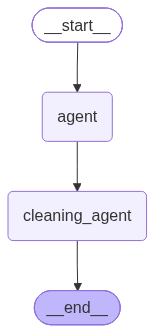

In [9]:
from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

In [156]:
from langchain_mistralai import ChatMistralAI
llm = ChatMistralAI(
    model="ministral-14b-latest",
    temperature=0,
    api_key="wj9gV0n1cuu3Jv0E5pm7gvBmRyzCVIyT"
)
llm.invoke('HI')

AIMessage(content='Hello! 😊 How can I assist you today? Whether you have a question, need help with something, or just want to chat—I\'m here for it!\n\n(Or if you meant something specific with "HI," let me know!)', additional_kwargs={}, response_metadata={'token_usage': {'prompt_tokens': 4, 'total_tokens': 54, 'completion_tokens': 50, 'prompt_tokens_details': {'cached_tokens': 0}, 'service_tier': 'standard'}, 'model_name': 'ministral-14b-latest', 'model': 'ministral-14b-latest', 'finish_reason': 'stop', 'model_provider': 'mistralai'}, id='lc_run--01a08755-ec66-7cd1-8744-7780468c68e5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 4, 'output_tokens': 50, 'total_tokens': 54})

In [157]:
EVALUATION_SYSTEM_PROMPT = """
You are a strict data quality auditor.

You will be given:

1. The original dataset summary
2. The current dataset summary after the latest cleaning attempt
3. The cleaning/evaluation history

Your job is to determine whether the dataset needs another cleaning iteration.

Compare the original problems with the current dataset.

Check specifically:
- Are missing values resolved or acceptably handled?
- Are duplicates removed?
- Are dtypes corrected?
- Are numeric-looking/date-looking columns converted?
- Are constant or unnecessary columns removed?
- Are high-severity outliers handled?
- Were any new issues introduced?
- Are there still important data quality problems?

IMPORTANT:
If important cleaning problems remain, answer YES.
If the dataset is sufficiently clean and no important issues remain, answer NO.

Respond in EXACTLY this format:

IS_CLEANING_AGAIN_NEEDED: YES or NO
REASON: <short explanation, 2-4 sentences>
REMAINING_ISSUES:
- <issue 1>
- <issue 2>
- <issue 3>

If there are no remaining issues, write:

REMAINING_ISSUES:
- None
"""

In [158]:
cleaned_summary=summarize_csv("cleaned_output.csv")

C:\Users\paras\AppData\Local\Temp\ipykernel_12964\4126380093.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
C:\Users\paras\AppData\Local\Temp\ipykernel_12964\4126380093.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
C:\Users\paras\AppData\Local\Temp\ipykernel_12964\4126380093.py:111: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  convertible = pd.to_datetime(non_null, errors="coerce").notna().mean()
C:\Users\paras\AppData

In [159]:


eval_prompt = ChatPromptTemplate.from_messages([
    ("system", EVALUATION_SYSTEM_PROMPT),
    MessagesPlaceholder(variable_name="messages"),
])
eval_chain = eval_prompt | llm


combined_input = f"""
    Original Dataset Summary :
    {dataset_summary}

    (CLEANED) DATASET SUMMARY:
    {cleaned_summary}

    Evaluate whether the cleaning was successful, following the exact format instructed."""


response = eval_chain.invoke({"messages": [HumanMessage(content=combined_input)]})
print(response.content)

**IS_CLEANING_AGAIN_NEEDED: YES**
**REASON:**
The duplicate row was successfully removed, and no missing values or dtype issues remain. However, **a critical issue persists in the `Relationship_Status` column**, where the original dataset had **3 unique values** ("Single," "In Relationship," "Complicated"), but the cleaned dataset now shows **only 2 unique values** ("Single," "In Relationship"). The "Complicated" category (32 rows) appears to have been **dropped entirely**, which is a **data integrity violation** and likely unintentional. This could distort analysis, especially for relationship dynamics.

---
**REMAINING_ISSUES:**
- **Lost categorical values in `Relationship_Status`**: The "Complicated" category (32 rows) is missing in the cleaned dataset, suggesting a filtering or encoding error.
- **No validation of logical consistency**: While outliers and dtypes are clean, no checks were performed to ensure **realistic value ranges** (e.g., `Sleep_Hours_Per_Night` max of 9.6 is pla

In [ ]:
df=pd.read_csv("cleaned_output.csv")
df['Most_Used_Platform'].unique()
df.duplicated().sum( )

array(['Instagram', 'Twitter', 'Tiktok', 'YouTube', 'Facebook',
       'Linkedin', 'Snapchat', 'Line', 'Kakaotalk', 'Vkontakte',
       'Whatsapp', 'Wechat'], dtype=object)